   income  total_debt  late_payments  employment_years  loan_amount  \
0  141958       74770              3                18       164236   
1   35795       92055              0                17        43562   
2   20860       27966              7                 9        25169   
3  123694       82709              5                 6       195930   
4  148106       60889              5                 8        26604   

   loan_term_months employment_status  debt_to_income  creditworthy  
0                36          Employed        0.558842             1  
1                36          Employed        2.605533             0  
2                24          Employed        1.390926             0  
3                48        Unemployed        0.701658             0  
4                60        Unemployed        0.414112             1  
Dataset Shape: (3000, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):


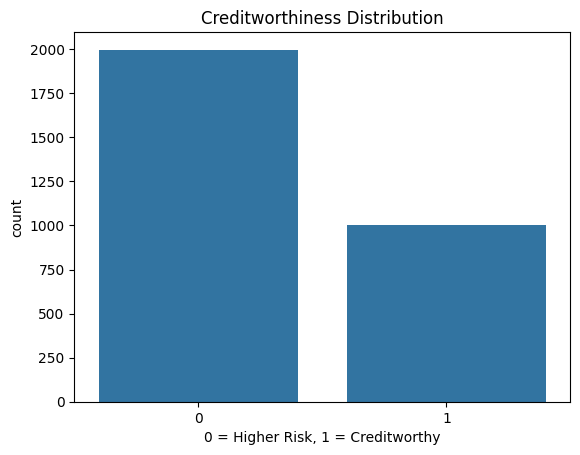

Training Data: (2400, 8)
Testing Data: (600, 8)
Logistic Regression Training Completed!
Decision Tree Training Completed!
Random Forest Training Completed!
                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0  Logistic Regression     0.763      0.611   0.806     0.695    0.858
1        Decision Tree     0.707      0.550   0.687     0.611    0.735
2        Random Forest     0.767      0.645   0.677     0.660    0.839


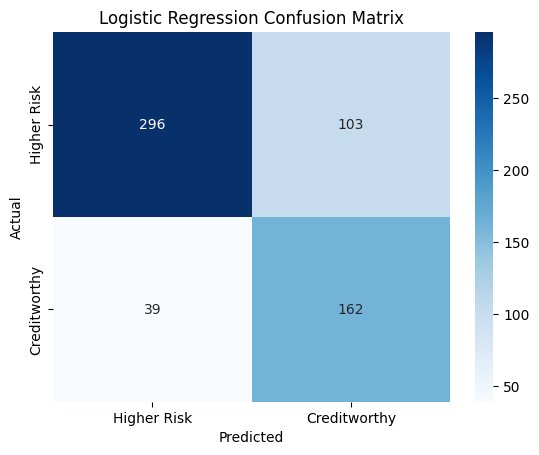

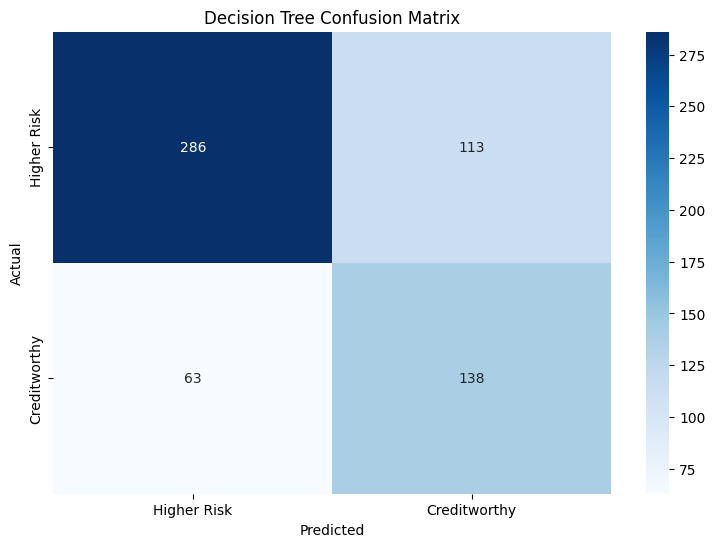

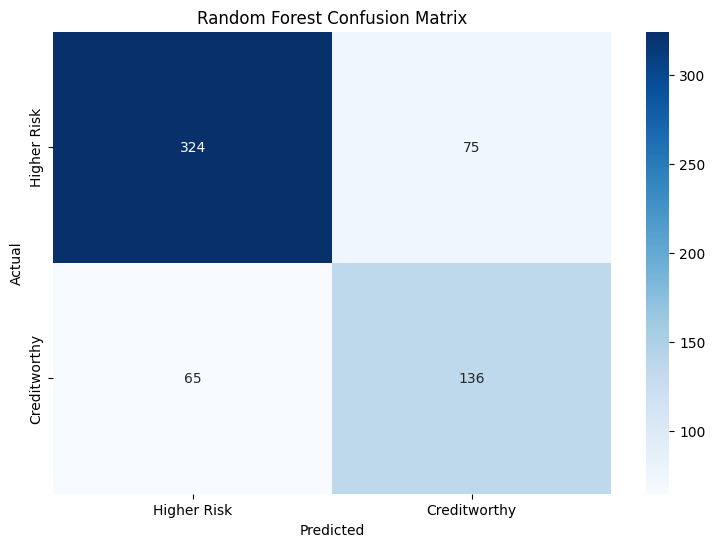

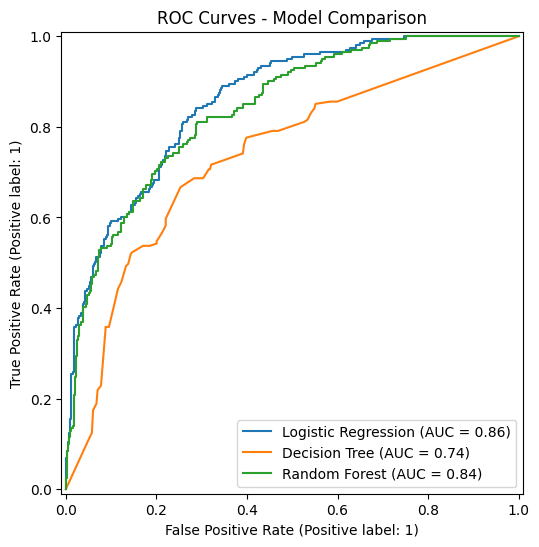

Best Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

 Higher Risk       0.88      0.74      0.81       399
Creditworthy       0.61      0.81      0.70       201

    accuracy                           0.76       600
   macro avg       0.75      0.77      0.75       600
weighted avg       0.79      0.76      0.77       600

Creditworthiness Prediction:
Creditworthy
Predicted Probability of Creditworthy Class: 89.48 %


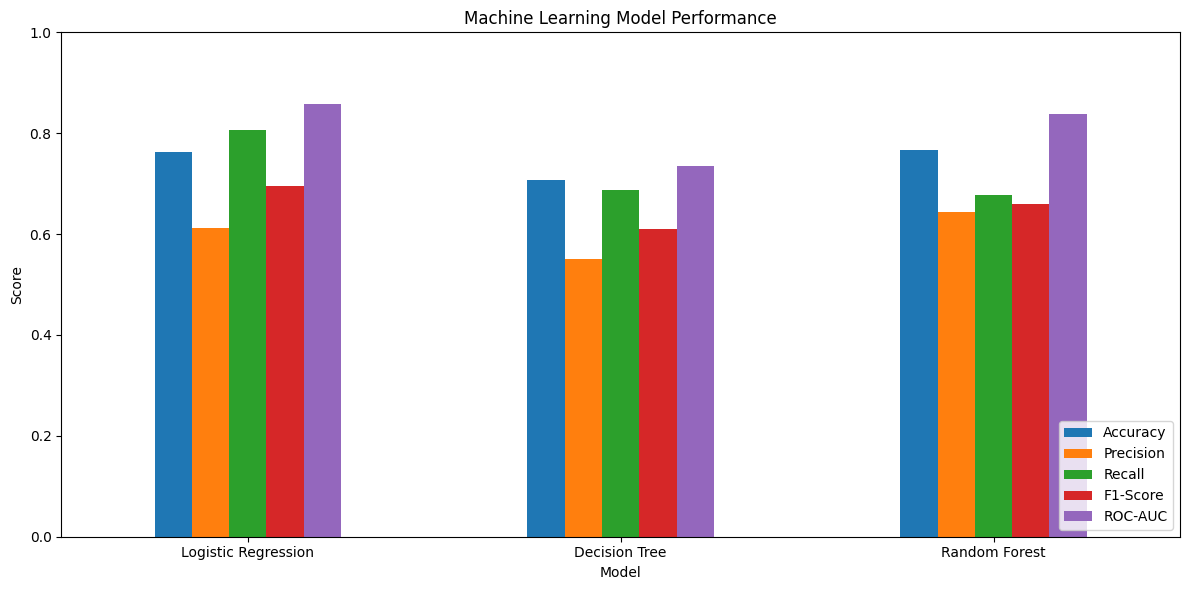

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

np.random.seed(42)

n = 3000

data = pd.DataFrame({
    "income": np.random.randint(20000, 150000, n),
    "total_debt": np.random.randint(1000, 100000, n),
    "late_payments": np.random.randint(0, 10, n),
    "employment_years": np.random.randint(0, 25, n),
    "loan_amount": np.random.randint(5000, 200000, n),
    "loan_term_months": np.random.choice([12, 24, 36, 48, 60], n),
    "employment_status": np.random.choice(
        ["Employed", "Self-Employed", "Unemployed"],
        n,
        p=[0.65, 0.25, 0.10]
    )
})

# Feature engineering
data["debt_to_income"] = (
    data["total_debt"] +
    data["loan_amount"] / data["loan_term_months"]
) / data["income"]

# Generate sample creditworthiness labels
risk_score = (
    -2.0
    + 3.0 * data["debt_to_income"]
    + 0.30 * data["late_payments"]
    - 0.035 * data["employment_years"]
    + 0.9 * (data["employment_status"] == "Unemployed")
    - 0.3 * (data["employment_status"] == "Employed")
)

probability = 1 / (1 + np.exp(risk_score))

data["creditworthy"] = (
    np.random.random(n) < probability
).astype(int)

print(data.head())

print("Dataset Shape:", data.shape)

print("\nDataset Information:")
print(data.info())

print("\nMissing Values:")
print(data.isnull().sum())

print("\nStatistical Summary:")
print(data.describe())

print("\nCreditworthiness Distribution:")
print(data["creditworthy"].value_counts())

sns.countplot(
    data=data,
    x="creditworthy"
)

plt.title("Creditworthiness Distribution")
plt.xlabel("0 = Higher Risk, 1 = Creditworthy")
plt.show()

X = data.drop("creditworthy", axis=1)

y = data["creditworthy"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

numeric_features = [
    "income",
    "total_debt",
    "late_payments",
    "employment_years",
    "loan_amount",
    "loan_term_months",
    "debt_to_income"
]

categorical_features = [
    "employment_status"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        class_weight="balanced",
        random_state=42
    )
}

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "Training Completed!")

    results = []

for name, model in trained_models.items():

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    roc_auc = roc_auc_score(y_test, probabilities)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))

for name, model in trained_models.items():

    predictions = model.predict(X_test)

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Higher Risk", "Creditworthy"],
        yticklabels=["Higher Risk", "Creditworthy"]
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    plt.figure(figsize=(9, 6))

for name, model in trained_models.items():

    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=plt.gca()
    )

plt.title("ROC Curves - Model Comparison")
plt.show()

best_model_name = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

print("\nClassification Report:")

print(classification_report(
    y_test,
    best_model.predict(X_test),
    target_names=["Higher Risk", "Creditworthy"]
))

new_person = pd.DataFrame({
    "income": [80000],
    "total_debt": [15000],
    "late_payments": [1],
    "employment_years": [5],
    "loan_amount": [30000],
    "loan_term_months": [36],
    "employment_status": ["Employed"]
})

# Feature engineering
new_person["debt_to_income"] = (
    new_person["total_debt"] +
    new_person["loan_amount"] /
    new_person["loan_term_months"]
) / new_person["income"]

# Predict
prediction = best_model.predict(new_person)[0]

probability = best_model.predict_proba(new_person)[0][1]

print("Creditworthiness Prediction:")

if prediction == 1:
    print("Creditworthy")
else:
    print("Potential Higher Credit Risk")

print("Predicted Probability of Creditworthy Class:",
      round(probability * 100, 2), "%")

results_df.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()
